# ***PROJECT OBJECTIVES***

The goal of this project is to analyze customer reviews for the company UGC (cinemas).

* **Exploratory Data Analysis (EDA):** We will first explore the dataset to understand the distribution of reviews and ratings, and to quickly identify potential factors influencing the rating based on user text.
* **Topic Modeling:** Secondly, we will attempt to model the different topics highlighted in these reviews (e.g., cleanliness, welcome/staff, price, etc.).
* **Sentiment Analysis (Classification):** Finally, the project will conclude with a sentiment analysis task where the objective is to predict a review's rating using *only* its text content.

#

# ***IMPORTATIONS***

In [1]:
# ==============================================================================
# 1. CORE UTILITIES & DATA MANIPULATION
# ==============================================================================
import pandas as pd
import numpy as np
import warnings
from tqdm import tqdm

# Initialize tqdm for pandas progress bars
tqdm.pandas()

# Filter out warnings for a cleaner output
warnings.filterwarnings("ignore")

# ==============================================================================
# 2. DATA VISUALIZATION
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import pyLDAvis
import pyLDAvis.lda_model

# ==============================================================================
# 3. NLP TOOLS (PREPROCESSING & DETECTION)
# ==============================================================================
import nltk
import simplemma
from nltk.corpus import stopwords
from langdetect import detect, DetectorFactory
from langdetect.lang_detect_exception import LangDetectException

# Reproducibility for language detection
DetectorFactory.seed = 24
nltk.download('stopwords', quiet=True)

# ==============================================================================
# 4. MACHINE LEARNING (SKLEARN & XGBOOST)
# ==============================================================================
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    classification_report, 
    confusion_matrix, 
    ConfusionMatrixDisplay, 
    accuracy_score
)

from xgboost import XGBClassifier

# ==============================================================================
# 5. ADVANCED TOPIC MODELING (BERTopic)
# ==============================================================================
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from umap import UMAP
from hdbscan import HDBSCAN

# ==============================================================================
# 6. DEEP LEARNING (TRANSFORMERS & PYTORCH)
# ==============================================================================
import torch
import evaluate
from datasets import Dataset
from transformers import (
    AutoTokenizer, 
    AutoModelForSequenceClassification, 
    TrainingArguments, 
    Trainer
)

In [2]:
if torch.cuda.is_available():
    print(f"GPU detected: {torch.cuda.get_device_name(0)}")
else:
    print("No GPU found, using CPU.")

GPU detected: NVIDIA GeForce RTX 4070 Laptop GPU


#

# ***DATA EXPLORATION***

### **DATA LOADING**

The data used in this project consists of Google Maps reviews for various UGC cinemas across France. I collected this data using a custom Python script. 

The dataset contains the following information:
* **Rating**: The score given by the user.
* **Date**: When the review was posted.
* **Likes**: The number of likes the review received.
* **Username**: The name of the reviewer.
* **User's Total Reviews**: The total number of reviews this user has left on Google Maps.
* **User's Total Photos**: The total number of photos this user has posted on Google Maps.
* **Cinema Name**: The specific UGC cinema being reviewed.

In [3]:
# Load the dataset from the CSV file into a pandas DataFrame
df = pd.read_csv('Data/avis_ugc.csv')

# Display the first 5 rows to get a quick overview of the data and columns
display(df.head())

# Print the number of rows and columns to understand the size of our dataset
print(f"Dataset shape (rows, columns): {df.shape}")

,rating,date,review,likes,user_name,user_nb_reviews,user_nb_photos,cinéma,language
0,1,2024-11-10T07:41:44.880Z,Il n’a pas admissible qu’une grosse chaîne de ...,0,anne degroux,2,0,UGC Ciné Cité Les Halles,fr
1,4,2024-11-09T10:32:32.722Z,"Pratique, plein de salles et bonne programmati...",0,Géraldine Sauvenay,3,0,UGC Ciné Cité Les Halles,fr
2,3,2024-11-09T08:45:17.039Z,"Nettoyez vos écrans, ça commence à se voir !",0,M G,2,0,UGC Ciné Cité Les Halles,fr
3,1,2024-11-08T20:13:38.816Z,The theater still has a bed bug problem. Sat d...,0,Cordelia Ryan,2,1,UGC Ciné Cité Les Halles,fr
4,1,2024-11-08T15:32:14.074Z,VOLUME beaucoup trop fort mon dieu!! On était ...,0,Spei,83,0,UGC Ciné Cité Les Halles,fr


Dataset shape (rows, columns): (203186, 9)


#

### **DATA QUALITY & CLEANING**

Now that our data is loaded, we need to check its quality. We will explore the dataset to find any missing values, duplicates, or inconsistencies. 

This is a crucial step because bad data will lead to poor results in our analysis and machine learning models (the "Garbage In, Garbage Out" principle).

In [4]:
# Check the data type of each column
print("Data types:")
display(df.dtypes)

# Convert the 'date' column to datetime format for easier manipulation later
df['date'] = pd.to_datetime(df['date'])

# Check the percentage of missing values in each column
print("\nPercentage of missing values per column:")
display(df.isna().mean() * 100) 

# About 60% of the rows don't have a review text. 
# Since our goal is text analysis, we drop these missing values.
# (Best practice: use subset=['review'] if your text column is named 'review' to only drop rows missing the text)
df = df.dropna()

# Check for duplicated rows
print(f'\nNumber of duplicated rows: {df.duplicated().sum()}')

# Remove the duplicated rows (these often happen during data scraping)
df = df.drop_duplicates()

Data types:


rating              int64
date               object
review             object
likes               int64
user_name          object
user_nb_reviews     int64
user_nb_photos      int64
cinéma             object
language           object
dtype: object


Percentage of missing values per column:


rating              0.000000
date                0.000000
review             57.043300
likes               0.000000
user_name           0.000984
user_nb_reviews     0.000000
user_nb_photos      0.000000
cinéma              0.000000
language            0.000000
dtype: float64


Number of duplicated rows: 560


In [5]:
# Statistical summary for NUMERICAL columns (Rating, Likes, etc.)
print("--- Summary of Numerical Columns ---")
display(df.describe()) 

# Statistical summary for TEXT / CATEGORICAL columns (Username, Cinema name, etc.)
print("\n--- Summary of Text Columns ---")
display(df.describe(include='object'))

--- Summary of Numerical Columns ---


,rating,likes,user_nb_reviews,user_nb_photos
count,86720.000000,86720.000000,86720.000000,86720.000000
mean,3.776303,0.368658,94.397740,214.969188
std,1.321713,1.749008,139.429774,1692.644356
min,1.000000,0.000000,0.000000,0.000000
25%,3.000000,0.000000,17.000000,0.000000
50%,4.000000,0.000000,48.000000,9.000000
75%,5.000000,0.000000,116.000000,75.000000
max,5.000000,53.000000,3730.000000,200769.000000



--- Summary of Text Columns ---


,review,user_name,cinéma,language
count,86720,86720,86720,86720
unique,42338,40977,37,2
top,Bien,Thomas,UGC Ciné Cité Les Halles,fr
freq,622,40,8520,46987


### **FIRST OBSERVATIONS**

We can already spot some interesting insights from our data summaries:

* **Top Cinema:** As expected, the most reviewed cinema (making up almost 10% of the dataset) is the most visited one globally.
* **Language:** French is the dominant language (nearly 50% of the reviews). 
  > *Methodology Note: To get good results with our NLP models later, we MUST filter the dataset to keep ONLY French reviews. Mixing languages ruins topic modeling.*
* **Average Rating:** The average score is around 3.8/5, which is moderate and leaves room for improvement.
* **Short Reviews:** Many reviews are identical and very short, often just the word "Bien" (Good). 
  > *Methodology Note: We should filter out these very short reviews later. Models like LDA and BERTopic need enough words to understand the context and find meaningful topics.*
* **Usernames:** Usernames are not unique, meaning some users have left multiple reviews.
* **Outliers:** There are extreme outliers in user behavior. For example, one user posted over 200,000 photos! However, since our main goal is Text Analysis (NLP), we won't worry about these numerical outliers for now.

#

### **DATA VISUALIZATION**

The goal of this section is to dive deeper into our data to understand the relationships between different variables. By visualizing the data, we can easily spot trends, patterns, and potential correlations that will guide our NLP analysis and machine learning models.

#### *Target variable analysis*

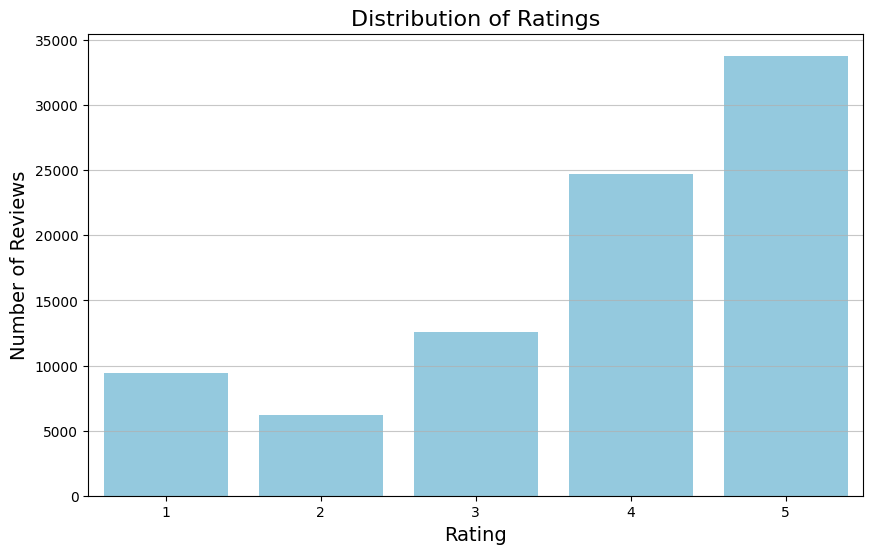

In [6]:
plt.figure(figsize=(10, 6))

# Create a bar chart to count the number of reviews for each rating (1 to 5)
sns.countplot(data=df, x='rating', color='skyblue')

plt.title('Distribution of Ratings', fontsize=16)
plt.xlabel('Rating', fontsize=14)
plt.ylabel('Number of Reviews', fontsize=14)

plt.grid(axis='y', alpha=0.7)

plt.show()

This graph shows how the user ratings are distributed. 

* **High Satisfaction:** There is a strong concentration of positive reviews. The 5-star rating is the most frequent (nearly 35,000 reviews), followed by the 4-star rating (around 25,000 reviews).
* **Polarization:** Lower ratings (1 and 2) are much less frequent, but there are noticeably more 1-star reviews than 2-star reviews. This suggests that unhappy customers tend to give the lowest possible score.

 > This graph highlights a severe **Class Imbalance**. Because there are so many more positive reviews than negative ones, our future predictive model might become biased (it might just predict "5" for everything). We will need to handle this imbalance during the Sentiment Analysis modeling phase.

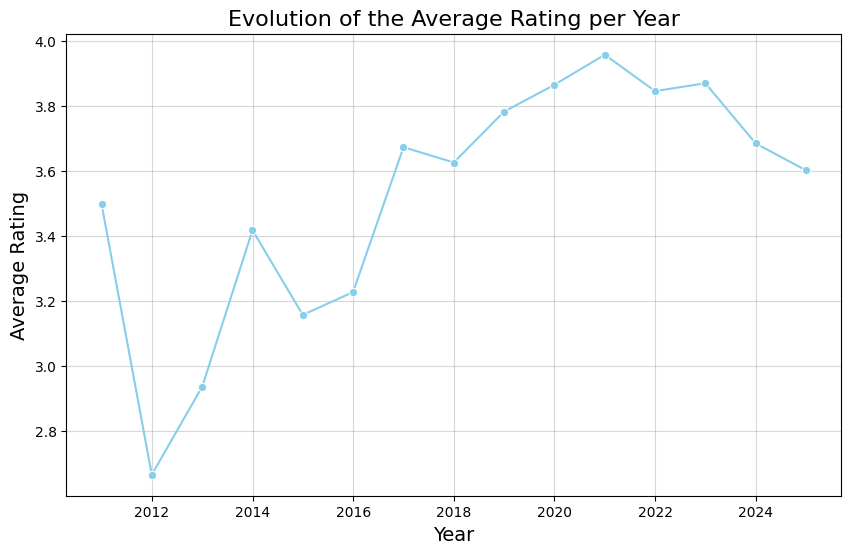

In [7]:
# Calculate the average rating for each year
avg_rating_per_year = df.groupby(pd.Grouper(key='date', freq='YE'))['rating'].mean().reset_index()

plt.figure(figsize=(10, 6))

# Create a line plot to show the evolution over time
sns.lineplot(data=avg_rating_per_year, x='date', y='rating', marker='o', color='skyblue')

plt.title("Evolution of the Average Rating per Year", fontsize=16)
plt.xlabel("Year", fontsize=14)
plt.ylabel("Average Rating", fontsize=14)

plt.grid(alpha=0.5)

plt.show()

This graph tracks how the average rating has changed over the years. 

* **Historical Fluctuations:** There was a significant drop in satisfaction around 2012-2013.
* **Peak Satisfaction:** Ratings improved steadily after 2013, reaching a peak (close to 4.0) between 2019 and 2021.
* **Recent Decline:** Since 2021, the average rating has started to decrease. This suggests that customers have been slightly less satisfied recently.

> While this trend is interesting, it is important to note that the **Year** will not be a feature in our final Sentiment Analysis model. Our goal is to predict the rating based purely on the text.
> From a business perspective, it would be highly valuable to isolate and analyze the texts of the most recent reviews (post-2021). Understanding *why* these recent ratings are dropping can highlight ongoing issues and provide actionable insights for the company.

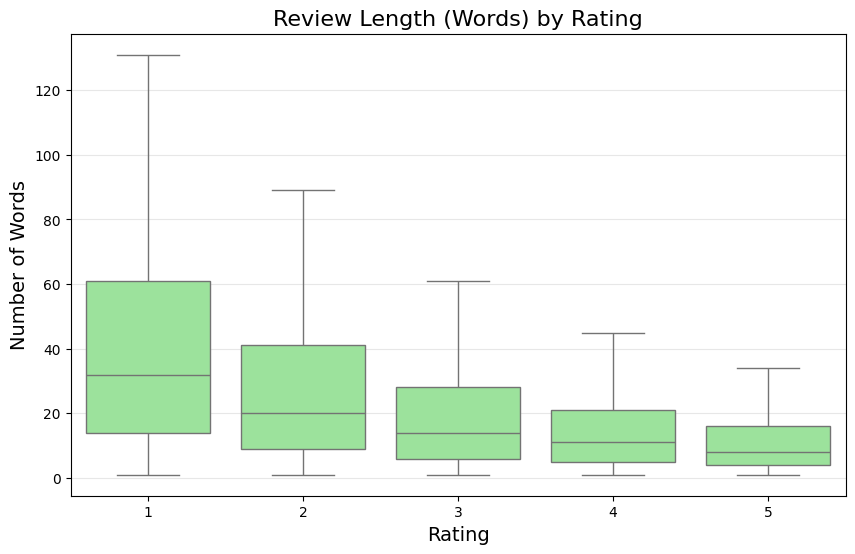

In [8]:
# Calculate the length of each review (number of words)
df['review_len'] = df['review'].apply(lambda x: len(str(x).split()))

plt.figure(figsize=(10, 6))

# Create a boxplot to see the distribution of length for each rating
sns.boxplot(data=df, x='rating', y='review_len', color='lightgreen', showfliers=False)

plt.title('Review Length (Words) by Rating', fontsize=16)
plt.xlabel('Rating', fontsize=14)
plt.ylabel('Number of Words', fontsize=14)

plt.grid(axis='y', alpha=0.3)

plt.show()

This graph explores the relationship between the length of a review (number of words) and the rating given by the user.

* **Negative Correlation:** We generally observe that lower ratings (1 and 2 stars) tend to have longer review texts. 
* **The "Vent" Factor:** This can be explained by consumer behavior: unhappy customers often write detailed reviews to explain exactly what went wrong, whereas satisfied customers are more likely to leave short, simple comments like "Great cinema" or "Good experience."

> Since many 5-star reviews are extremely short (only a few words), they might not provide much data for our Topic Modeling.

####  *Review analysis*

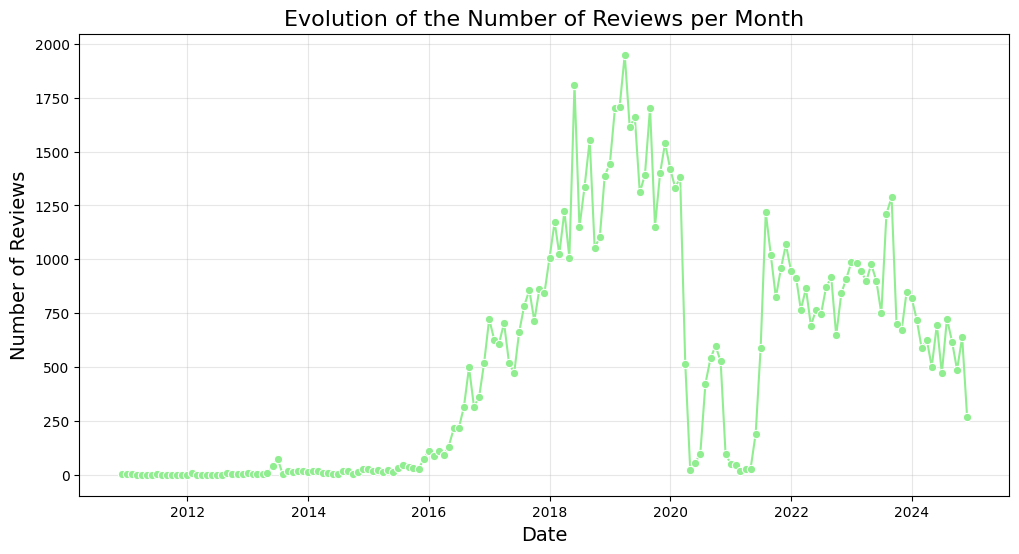

In [9]:
# Group by Month ('ME') and count the number of ratings to see the volume of activity
reviews_per_month = df.groupby(pd.Grouper(key='date', freq='ME'))['rating'].count().reset_index()

plt.figure(figsize=(12, 6))

# Create a line plot showing the volume of reviews over time
sns.lineplot(data=reviews_per_month, x='date', y='rating', marker='o', color='lightgreen')

plt.title("Evolution of the Number of Reviews per Month", fontsize=16)
plt.xlabel("Date", fontsize=14)
plt.ylabel("Number of Reviews", fontsize=14)

plt.grid(alpha=0.3)

plt.show()

This graph shows the total number of reviews posted each month. 

* **Growth in Data:** We can see how the frequency of reviews has changed. A sudden spike in the number of reviews usually indicates either a successful marketing period, a peak cinema season (like holidays), or a change in how Google prompts users for reviews.
* **Data Density:** This confirms that we have much more data for recent years than for the early 2010s.

> For a business, high volume means the data is more representative of current reality. 
> For our models, it is important to know that most of what the model learns will be based on recent customer behavior, as they represent the majority of our rows.

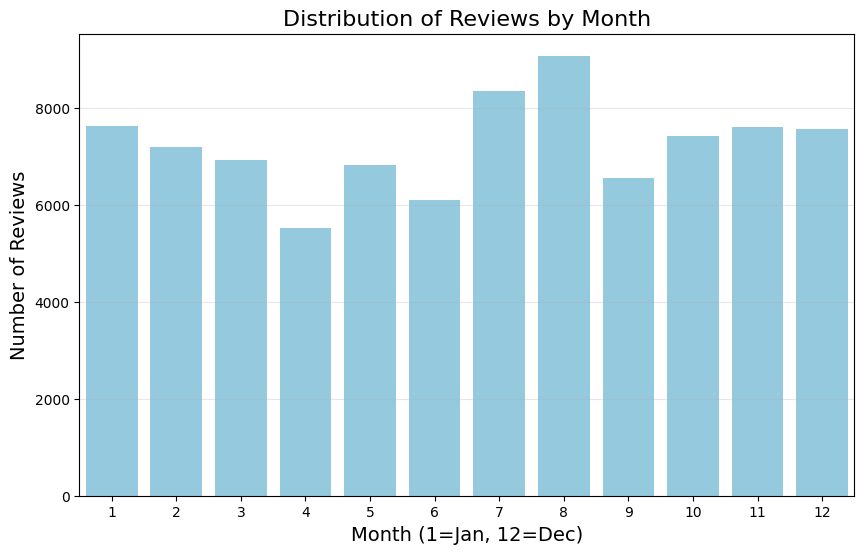

In [10]:
# Extract the month from the date column (1 = January, 12 = December)
df['month'] = df['date'].dt.month

plt.figure(figsize=(10, 6))

# Create a countplot to see which months get the most reviews
sns.countplot(data=df, x='month', color='skyblue')

plt.title('Distribution of Reviews by Month', fontsize=16)
plt.xlabel('Month (1=Jan, 12=Dec)', fontsize=14)
plt.ylabel('Number of Reviews', fontsize=14)

plt.grid(axis='y', alpha=0.3)

plt.show()

This graph shows the total volume of reviews aggregated by month across all years in the dataset.

* **Summer Peak:** We observe a moderate variation throughout the year, with a clear peak in **August** (over 8,000 reviews). This indicates higher cinema attendance and user engagement during the summer holidays.
* **Spring Low:** **April** has the lowest number of reviews (around 5,000), suggesting a quieter period for cinema-going or feedback.
* **General Stability:** Most other months remain relatively stable, with review counts ranging between 6,500 and 7,500.

> The seasonality in the data is clear. Higher volumes in August mean that our dataset is slightly more "weighted" toward summer experiences. 
> For the company, these peaks are the most critical times to maintain service quality, as the high volume of visitors increases the risk of negative feedback if the staff or facilities cannot handle the crowd.

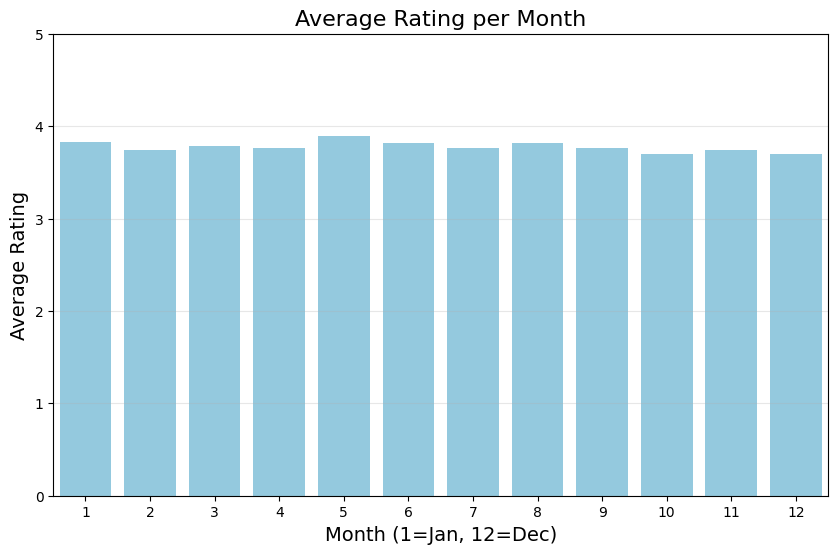

In [11]:
# Calculate the average rating for each month
avg_rating_per_month = df.groupby('month')['rating'].mean().reset_index()

plt.figure(figsize=(10, 6))

# Create a bar chart to compare average satisfaction across months
sns.barplot(data=avg_rating_per_month, x='month', y='rating', color='skyblue')

plt.title('Average Rating per Month', fontsize=16)
plt.xlabel('Month (1=Jan, 12=Dec)', fontsize=14)
plt.ylabel('Average Rating', fontsize=14)

plt.ylim(0, 5)
plt.grid(axis='y', alpha=0.3)

plt.show()

This graph shows the average user rating for each month of the year.

* **High Consistency:** The average rating remains very stable throughout the year, staying between 3.6 and 3.9. 
* **Summer Performance:** Despite August having the highest volume of reviews (as seen in the previous graph), the average rating does not drop significantly. This suggests that the cinemas handle the summer crowds reasonably well.

> For the business, this shows that satisfaction is not heavily dependent on the season. 

### *Users analysis*

--- Rating Statistics by User Type ---


,Average_Rating,Review_Count
user_type,,
Occasional,3.039830,8235
Regular,3.579726,16494
Frequent,3.867474,19981
Expert,3.954578,42006


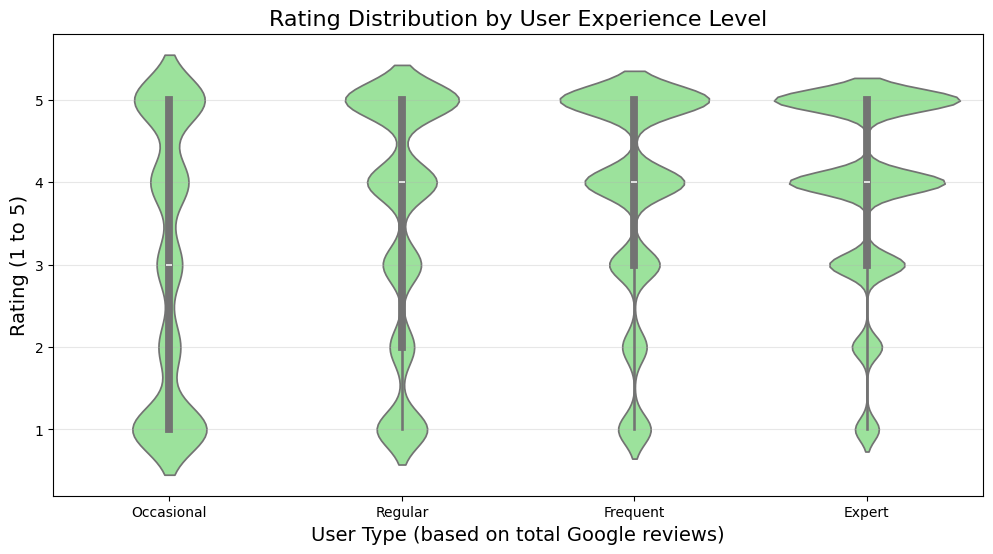

In [12]:
# 1Categorize users based on their total number of reviews
# Bins: 0-5 (Occasional), 6-20 (Regular), 21-50 (Frequent), 51+ (Expert)
bins = [0, 5, 20, 50, df['user_nb_reviews'].max()]
labels = ['Occasional', 'Regular', 'Frequent', 'Expert']
df['user_type'] = pd.cut(df['user_nb_reviews'], bins=bins, labels=labels)

# Display summary statistics for each user type
print("--- Rating Statistics by User Type ---")
user_stats = df.groupby('user_type').agg(
    Average_Rating=('rating', 'mean'),
    Review_Count=('rating', 'count')
)
display(user_stats)

# Visualization: Violin plot to see the rating distribution per type
plt.figure(figsize=(12, 6))
sns.violinplot(data=df, x='user_type', y='rating', color='lightgreen')

plt.title('Rating Distribution by User Experience Level', fontsize=16)
plt.xlabel('User Type (based on total Google reviews)', fontsize=14) 
plt.ylabel('Rating (1 to 5)', fontsize=14)
plt.grid(axis='y', alpha=0.3)

plt.show()

This visualization suggests a slight trend: users who post reviews frequently tend to leave higher ratings compared to those who post rarely.

* **Occasional Reviewers:** These users might only be motivated to leave a review when they have a specifically negative experience that "pushes" them to complain.
* **Frequent Reviewers:** For these users, leaving a review has become a habit. They rate their experiences systematically, including standard or positive visits, which naturally pulls their average rating higher.
* **Expert Consistency:** The "Expert" group shows a very concentrated density in the 4 and 5-star range, confirming that regular contributors are generally more "forgiving" or simply more balanced in their feedback.

> This is an interesting behavioral insight. It suggests that a low rating from an "Occasional" user might be a "cry for help" regarding a specific bad event, while a high rating from an "Expert" confirms a sustained quality of service that meets professional reviewer standards.
> 
> While this doesn't change our text processing strategy, it helps us weight the "importance" or the context of certain reviews.

#### *Analysis by cinema location*

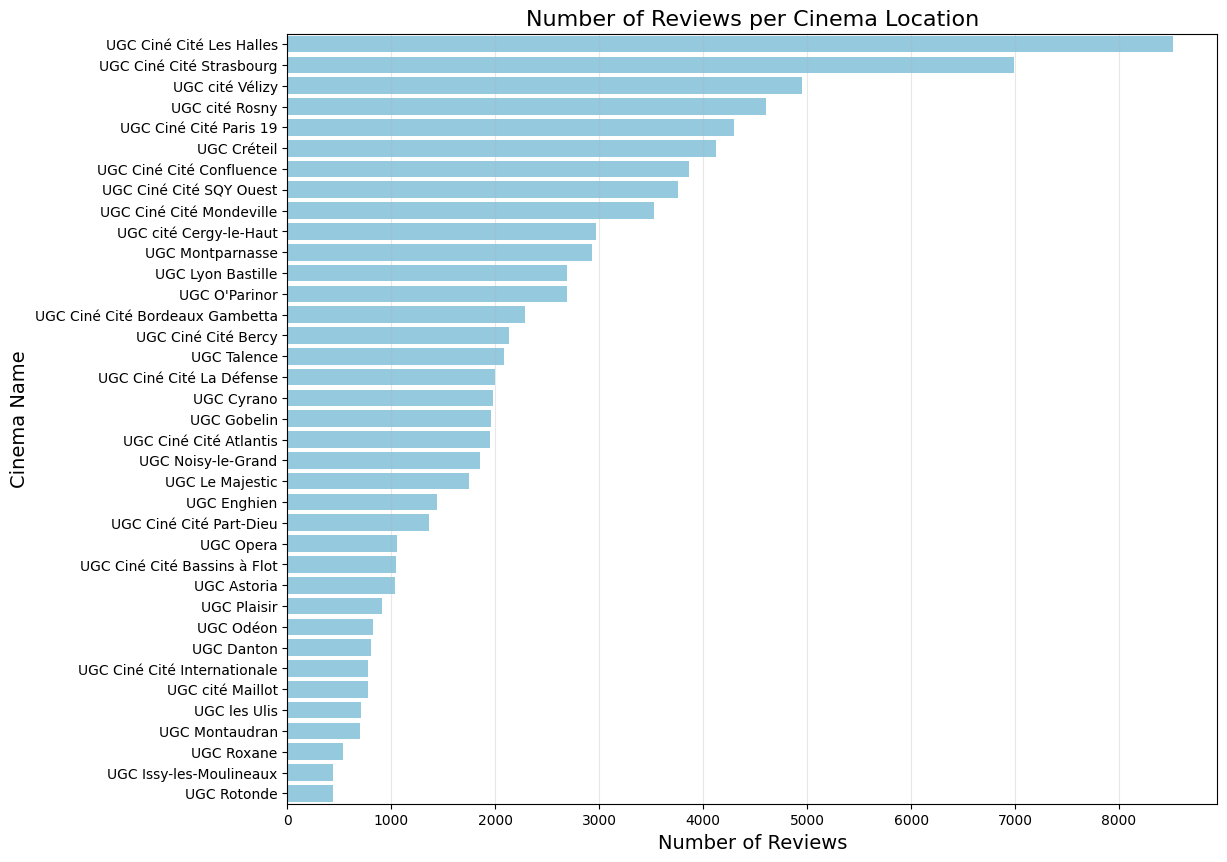

In [13]:
plt.figure(figsize=(12, 10))

# Create a horizontal bar chart
# We order the cinemas by review count (descending) for better readability
sns.countplot(
    data=df, 
    y="cinéma", 
    order=df['cinéma'].value_counts().index, 
    color='skyblue'
)

plt.title("Number of Reviews per Cinema Location", fontsize=16)
plt.xlabel("Number of Reviews", fontsize=14)
plt.ylabel("Cinema Name", fontsize=14)

plt.grid(axis='x', alpha=0.3)

plt.show()

This chart displays the number of reviews collected for each UGC cinema location.

* **High-Volume Hubs:** There is a significant disparity in review volume. The top cinemas attract thousands of reviews (e.g., UGC Ciné Cité Les Halles), while others have a much smaller digital footprint.
* **Data Representative Power:** Our global analysis and future topic models will be heavily influenced by these high-traffic locations. 
* **Potential Bias:** Cinemas with very few reviews (at the bottom of the chart) might show extreme average ratings because a single review has a disproportionate impact on their mean.

> Because the dataset is dominated by a few large cinemas, our results will naturally reflect the experience of "Big City" hubs. 
> It would be interesting to perform a comparative analysis between cinemas. Comparing the most reviewed vs. the least reviewed could reveal if certain issues are systemic across the whole UGC brand or limited to specific, overcrowded locations.

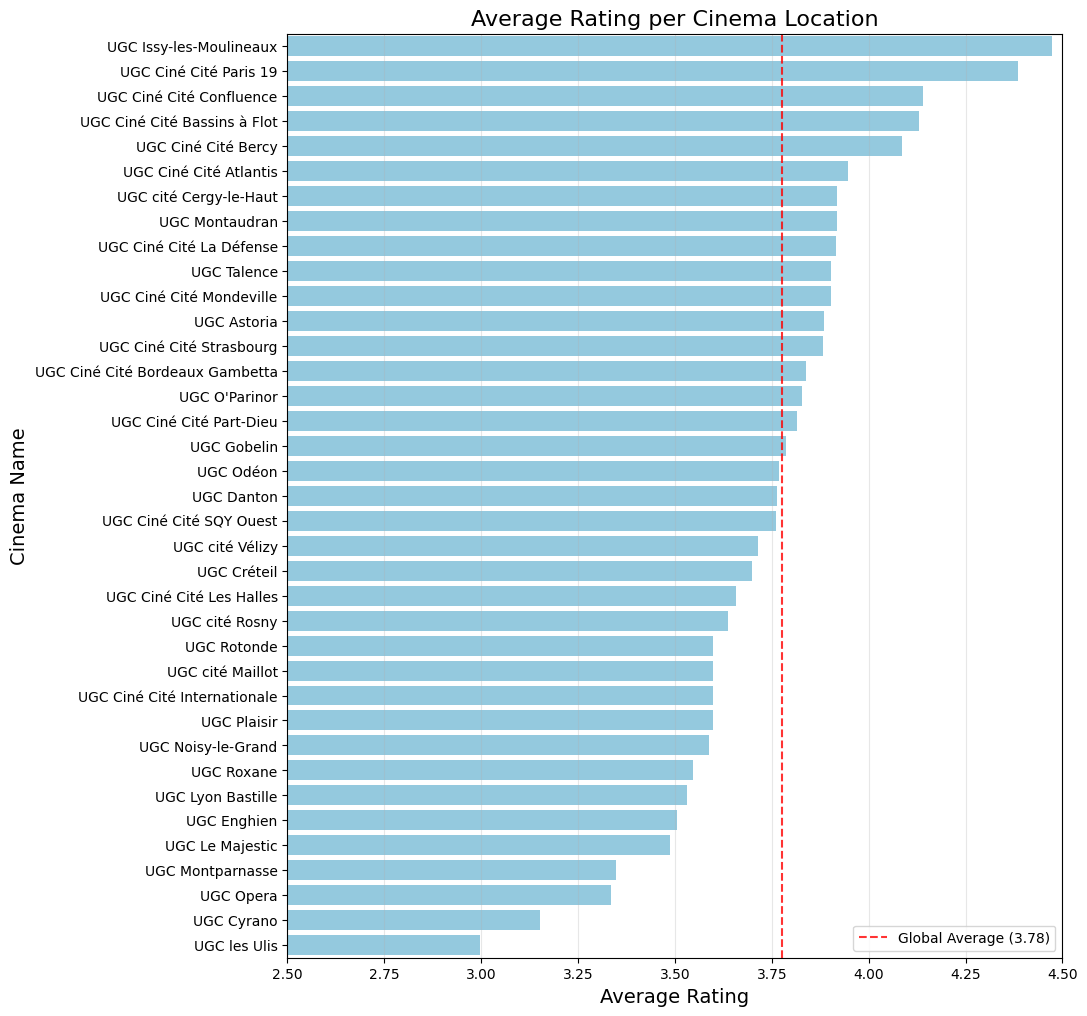

In [14]:
# Calculate the average rating for each cinema and sort them
cinema_avg_rating = df.groupby('cinéma')['rating'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 12))

# Create the horizontal bar plot
sns.barplot(x=cinema_avg_rating.values, y=cinema_avg_rating.index, color='skyblue')

global_mean = df['rating'].mean()
plt.axvline(x=global_mean, color='red', linestyle='--', alpha=0.8, label=f'Global Average ({global_mean:.2f})')

plt.title("Average Rating per Cinema Location", fontsize=16)
plt.xlabel("Average Rating", fontsize=14)
plt.ylabel("Cinema Name", fontsize=14)

plt.xlim(2.5, 4.5)
plt.legend(loc='lower right')
plt.grid(axis='x', alpha=0.3)

plt.show()

This graph compares the average satisfaction score across all UGC cinema locations, sorted from highest to lowest.

* **Performance Gap:** We observe a significant spread in quality. While the top-performing cinemas reach average scores above 4, the lowest-ranked locations sit around 3. This indicates that the "UGC experience" is not identical everywhere.
* **Benchmarking:** The red dashed line represents the global average (~3.8). This makes it easy to distinguish the "over-performers" from the "under-performers."
* **Actionable Insights:** The cinemas at the bottom of this list is critical and it would be interesting to find out *why* they are underperforming. Is it due to old facilities, staff issues, or specific local problems? Remark here we will do a global analysis but it can be note as a possible improvment.

> For the company, this is a "hit list" for operational improvements. 

#### *Text analysis*

In [15]:
# Setting a seed ensures that the language detection results are reproducible
DetectorFactory.seed = 24

def detect_language(text):
    """
    Detects the language of a given text.
    Returns the ISO 639-1 language code or None if detection fails.
    """
    if pd.isna(text) or not isinstance(text, str) or text.strip() == "":
        return None
        
    try:
        # We only need a small portion of long texts for detection to save time
        return detect(text)
    except LangDetectException:
        return None

# Apply the language detection
df['language_detected'] = df['review'].progress_map(detect_language)

# Display the distribution of detected languages
lang_distribution = df['language_detected'].value_counts(normalize=True) * 100
print("\nLanguage Distribution (%):")
print(lang_distribution.head())

100%|██████████| 86720/86720 [07:58<00:00, 181.21it/s]


Language Distribution (%):
language_detected
fr    86.175232
en     4.675718
de     1.409770
ca     1.194662
id     0.955267
Name: proportion, dtype: float64


100%|██████████| 86720/86720 [00:03<00:00, 24643.70it/s]


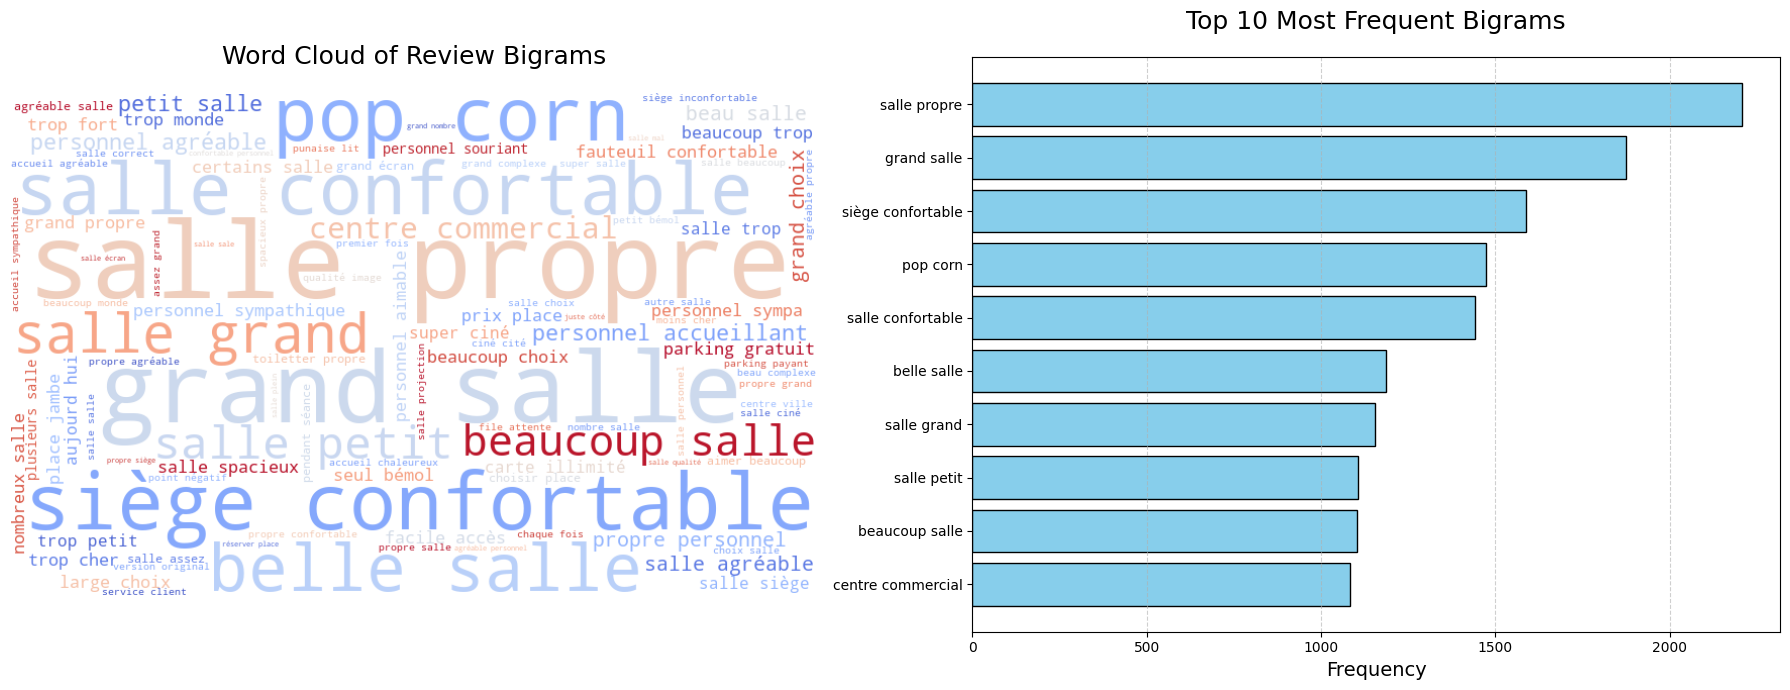

In [16]:
reviews_text = df['review']

# Stopwords
french_stopwords = stopwords.words('french')
custom_cinema_stopwords = [
    "cinéma", "cinema", "film", "films", "très", "bien", "plus", "ugc", 
    "bon", "bonne", "tout", "ça", "fait", "aller", "voir", "comme", 
    "aussi", "rien", "toujours", "si", "sans", "après", "avant", "peu", 
    "c'est", "être", "avoir", "faire", "lieu", "endroit", "vraiment", "car", "donc"
]
combined_stopwords = list(set(french_stopwords + custom_cinema_stopwords))

# Fast Lemmatization
tqdm.pandas()

def fast_lemmatize(text):
    # simplemma.text_lemmatizer returns a list of lemmas
    lemmas = simplemma.text_lemmatizer(text.lower(), lang='fr')
    # Filter out very short tokens and non-alphabetic strings
    return " ".join([l for l in lemmas if len(l) > 2 and l.isalpha()])

df['lemmatized_review'] = df['review'].progress_apply(fast_lemmatize)

# Vectorization (Bigrams)
vectorizer = CountVectorizer(
    stop_words=combined_stopwords, 
    max_features=100, 
    ngram_range=(2, 2) # Focusing on pairs of words for more context
)

# Frequency Calculation
X = vectorizer.fit_transform(df['lemmatized_review'])
word_frequencies = dict(zip(vectorizer.get_feature_names_out(), X.sum(axis=0).A1))

# --- Data Preparation for Visualization ---
sorted_freq = sorted(word_frequencies.items(), key=lambda x: x[1], reverse=True)[:10]
top_words, top_counts = zip(*reversed(sorted_freq))

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# WordCloud
wordcloud = WordCloud(width=800, height=500, background_color='white', 
                      colormap='coolwarm').generate_from_frequencies(word_frequencies)
axes[0].imshow(wordcloud, interpolation='bilinear')
axes[0].axis("off")
axes[0].set_title("Word Cloud of Review Bigrams", fontsize=18, pad=20)

# Bar Chart
axes[1].barh(top_words, top_counts, color='skyblue', edgecolor='black')
axes[1].set_title("Top 10 Most Frequent Bigrams", fontsize=18, pad=20)
axes[1].set_xlabel("Frequency", fontsize=14)
axes[1].grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

While the global bigram analysis gives us a general overview, it mixes positive and negative feedback. To get a clearer picture of what drives customer sentiment, we will now perform the same analysis filtered by rating.

* **The Goal:** Identify specific themes associated with extreme dissatisfaction (1-2 stars) versus high satisfaction (4-5 stars).
* **Hypothesis:** * **1-2 Stars:** We expect to see bigrams related to "propreté" (cleanliness), "prix élevé" (high price), or "personnel désagréable" (unfriendly staff).
    * **4-5 Stars:** We expect to see mentions of "confort siège" (seat comfort), "grand écran" (large screen), or "belle salle" (beautiful room).

> This step is crucial for the business. Instead of knowing that people talk about "salles," UGC will know exactly *what* is wrong with them in negative reviews and *what* to highlight in their marketing for positive ones.

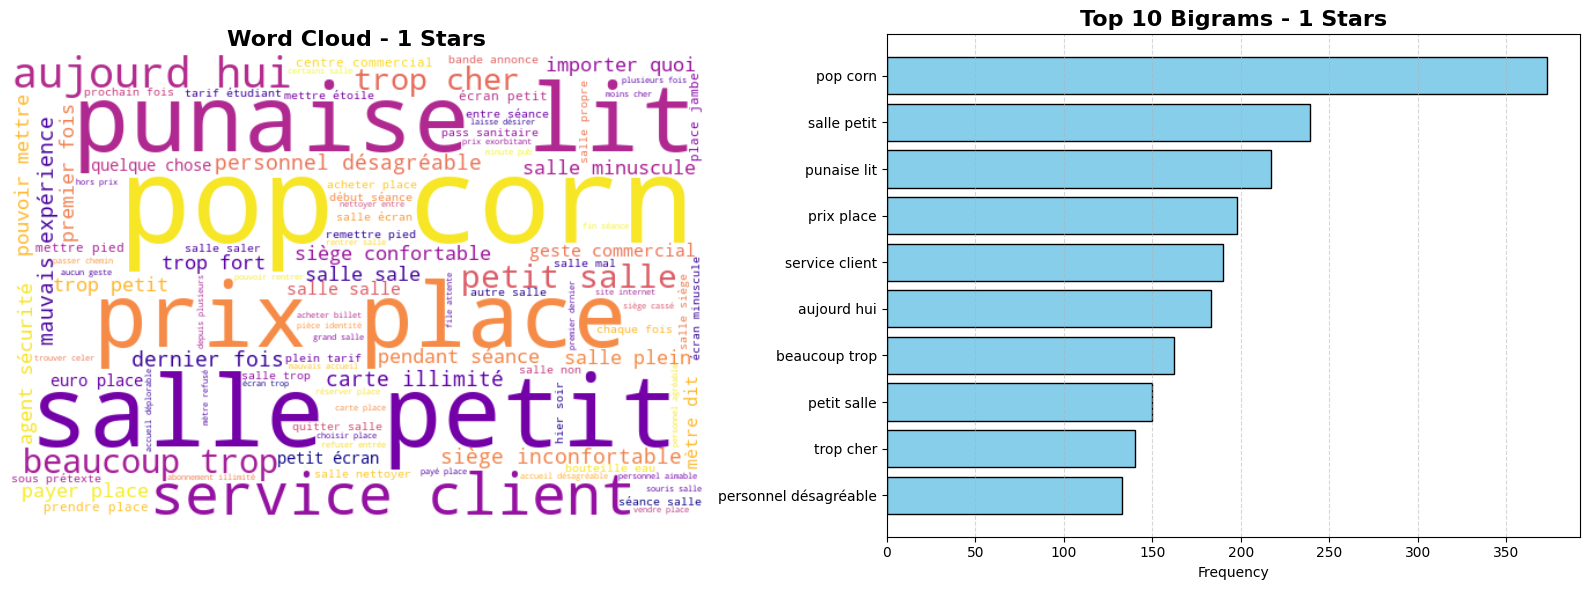

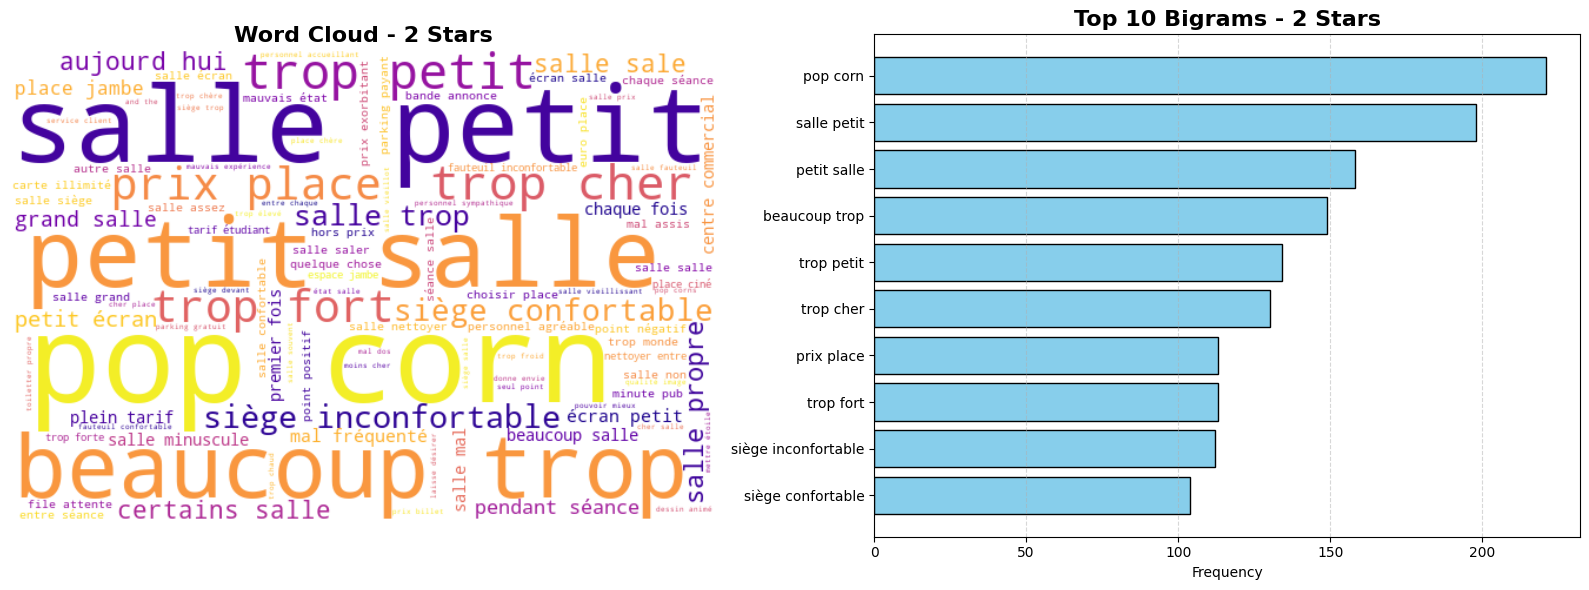

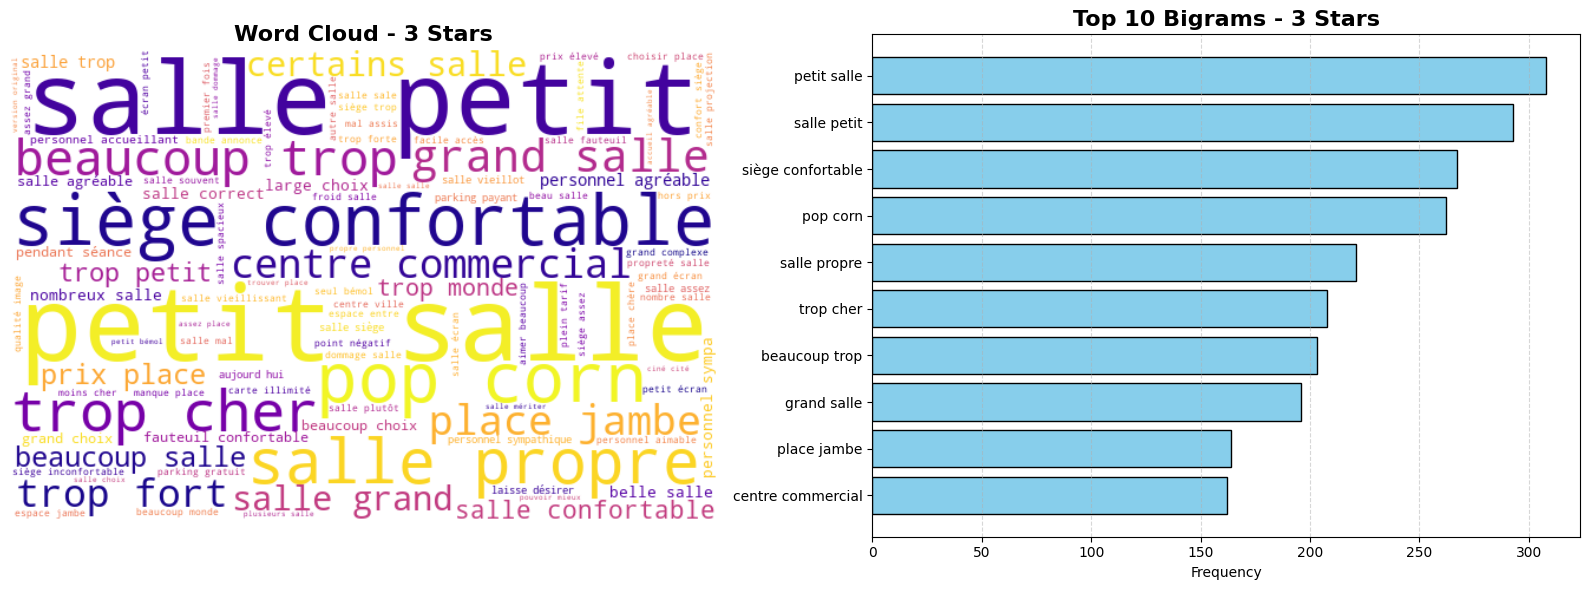

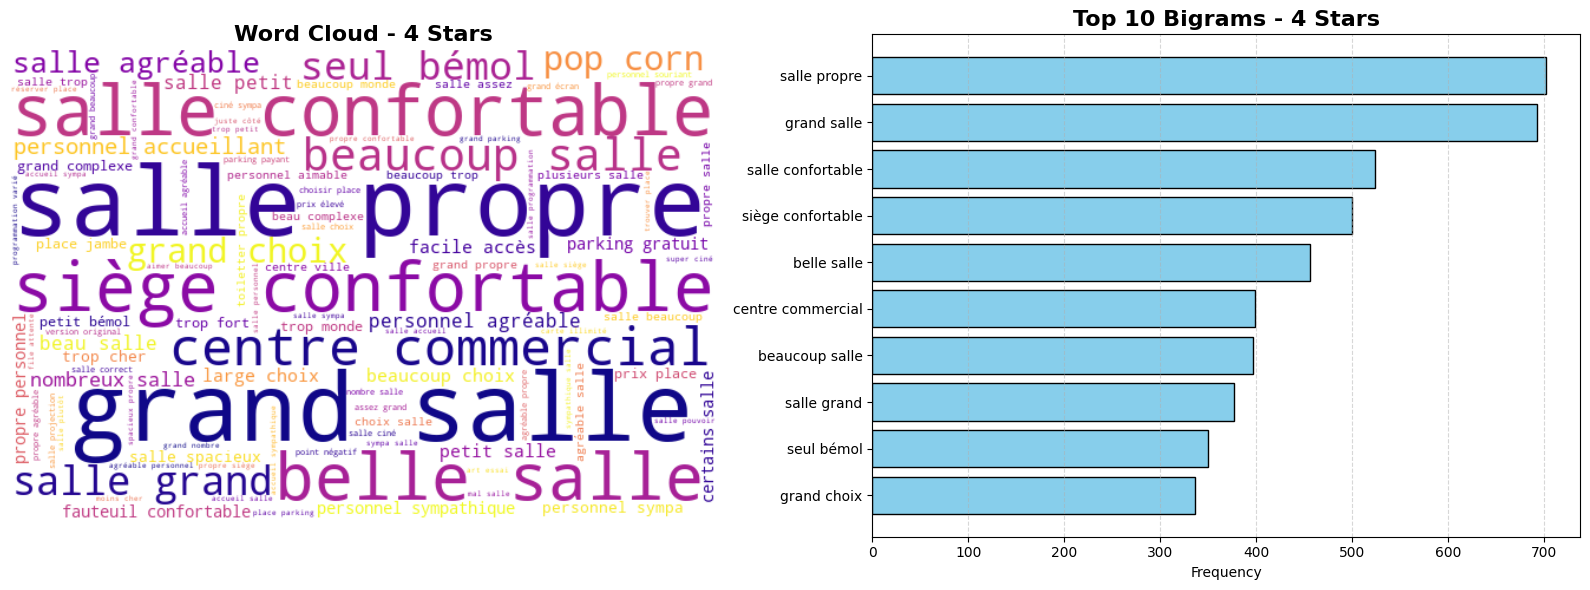

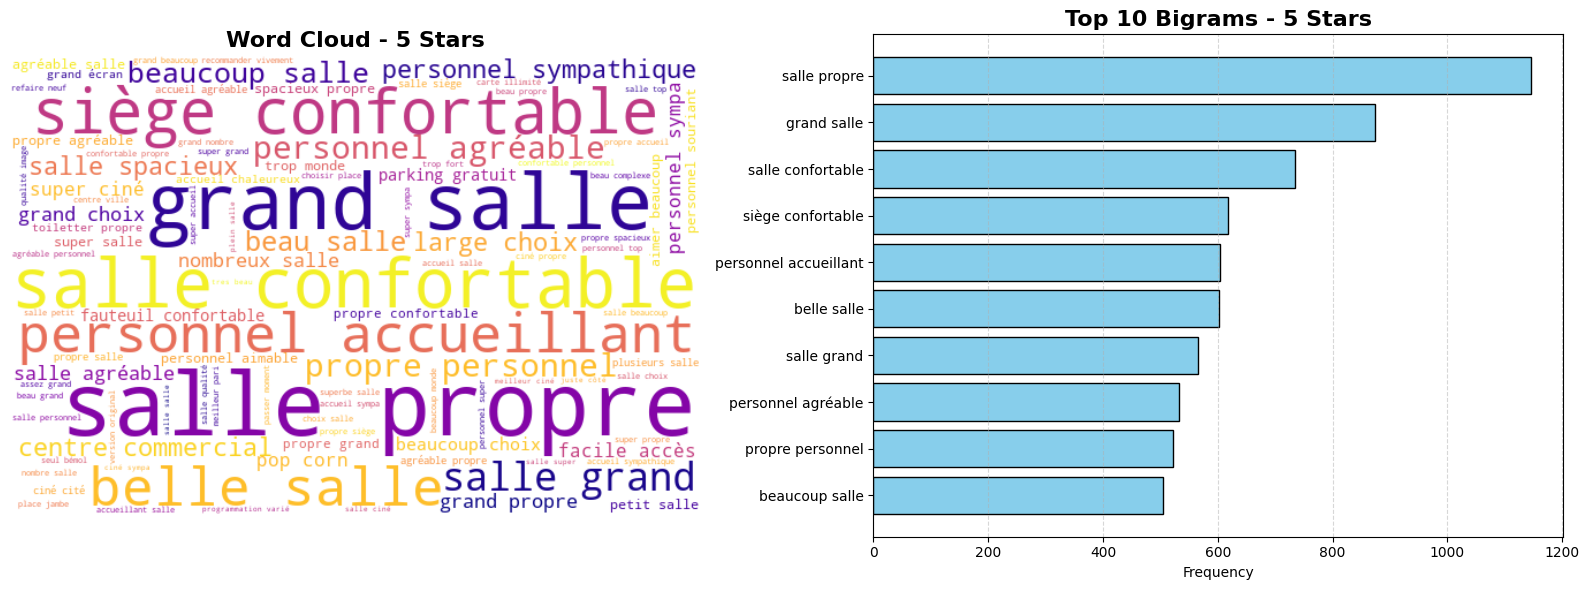

In [17]:
# Generating Visualizations per Rating
for rating in range(1, 6):
    df_rating = df[df['rating'] == rating]
    
    if df_rating.empty:
        continue
        
    reviews_text = df_rating['lemmatized_review']
    
    # Initialize Vectorizer for Bigrams
    vectorizer = CountVectorizer(
        stop_words=combined_stopwords, 
        max_features=100, 
        ngram_range=(2, 2)
    )

    X = vectorizer.fit_transform(reviews_text)
        
    # Frequencies
    words = vectorizer.get_feature_names_out()
    frequencies = X.sum(axis=0).A1
    word_frequencies = dict(zip(words, frequencies))

    # Top 10 sorting
    sorted_freq = sorted(word_frequencies.items(), key=lambda x: x[1], reverse=True)[:10]
    top_words, top_counts = zip(*reversed(sorted_freq))

    # Plotting
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # WordCloud
    wc = WordCloud(width=600, height=400, background_color='white', colormap='plasma').generate_from_frequencies(word_frequencies)
    axes[0].imshow(wc, interpolation='bilinear')
    axes[0].axis("off")
    axes[0].set_title(f"Word Cloud - {rating} Stars", fontsize=16, fontweight='bold')

    # Barplot
    axes[1].barh(top_words, top_counts, color='skyblue', edgecolor='black')
    axes[1].set_title(f"Top 10 Bigrams - {rating} Stars", fontsize=16, fontweight='bold')
    axes[1].set_xlabel("Frequency")
    axes[1].grid(axis='x', linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()

The comparative bigram analysis reveals a clear divide in user feedback. We can categorize the insights into three main pillars:

#### **1. The "Pain Points" (1-2 Stars)**
* **Hygiene & Maintenance:** "Salle sale" (dirty room) and the very specific "punaise lit" (bedbugs) are major red flags.
* **Pricing & Value:** "Trop cher" (too expensive) and "prix place" show a dissatisfaction with the price-to-quality ratio.
* **Staff Issues:** "Personnel désagréable" (unfriendly staff) is a recurring theme in the lowest ratings.

#### **2. The "Success Factors" (4-5 Stars)**
* **Infrastructure:** "Salle propre" (clean room), "grand écran" (large screen), and "siège confortable" (comfortable seat) are the drivers of satisfaction.
* **Location & Convenience:** The mention of "centre commercial" suggests that the proximity to shops and parking is a strong asset for certain locations.

#### **3. The Contradictions: A Case for Local Analysis**
* **The "Ambiguous" Themes:** Topics like **"taille salle"** (room size) and **"personnel"** (staff) appear in both categories. 
* **Conclusion:** This contradiction suggests that service quality is highly dependent on the specific cinema. A "small room" might be cozy in one location but cramped and frustrating in another. 

> Since the global analysis is contradictory, our next step should be to cross-reference these bigrams with specific cinema locations. This will allow us to identify exactly which cinemas are praised for their "accueil" and which ones are criticized for "propreté," moving from a general observation to a **targeted action plan**.

#

# **TOPIC MODELING**

In this section, we move beyond simple word counts to **unsupervised machine learning**. We want the computer to discover the hidden themes (topics) within our thousands of reviews automatically.

### **LDA (Latent Dirichlet Allocation)**

Training on 63871 documents and 11690 terms.
Calculating Log-Likelihood for different K...


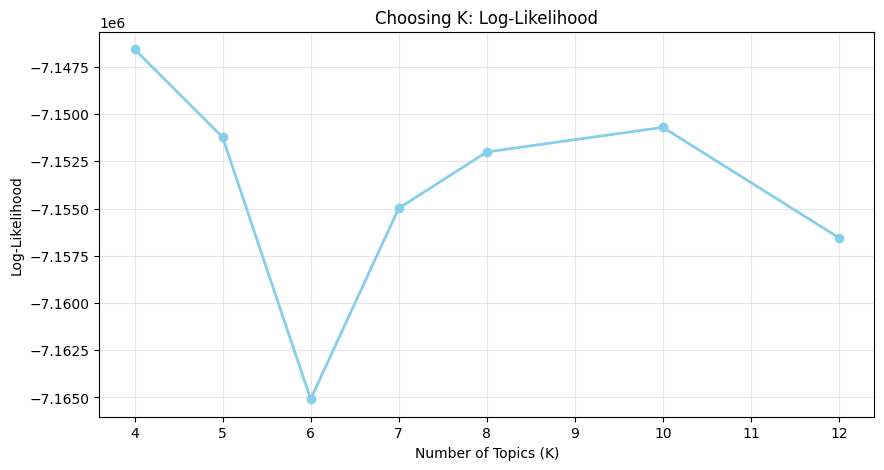


Final results for K=10:
--- Topic #1 ---
depuis | mètre | carte | client | personne | service | pouvoir | aucun | alors | ticket


--- Topic #2 ---
super | sympa | grand | propre | salle | confortable | assez | accès | situer | ciné


--- Topic #3 ---
salle | confortable | siège | petit | propre | top | siège confortable | qualité | programmation | correct


--- Topic #4 ---
grand | salle | beaucoup | parking | choix | beau | ciné | centre | spacieux | monde


--- Topic #5 ---
salle | aimer | contre | salle confortable | séance | quand | fois | autre | beaucoup | sortie


--- Topic #6 ---
pop | corn | pop corn | large | personnel | choix | souriant | aimable | proposer | inconfortable


--- Topic #7 ---
trop | cher | prix | tarif | salle | fort | tres | dernier | élevé | sale


--- Topic #8 ---
salle | séance | dommage | enfant | personne | entre | siège | beau | espace | moins


--- Topic #9 ---
place | pouvoir | jambe | écran | prix | séance | billet | ciné | vouloir | quand


--- T

In [18]:
# Rigorous Cleaning and Filtering
# We keep French and reviews with a minimum of "substance" (more than 3 words)
df_lda = df[(df['language_detected'] == 'fr') & (df['lemmatized_review'].str.split().str.len() > 3)].copy()

# Vectorization with Pruning
# max_df=0.85: ignore words present in more than 85% of reviews (too common)
# min_df=10: ignore words present in fewer than 10 reviews (too rare/noise)
vectorizer = CountVectorizer(
    stop_words=combined_stopwords, 
    ngram_range=(1, 2),
    max_df=0.85, 
    min_df=10  
)

dtm = vectorizer.fit_transform(df_lda['lemmatized_review'])

# Searching for the number of topics
search_range = [4, 5, 6, 7, 8, 10, 12]
log_likelihood_scores = []

print(f"Training on {dtm.shape[0]} documents and {dtm.shape[1]} terms.")
print("Calculating Log-Likelihood for different K...")

for k in search_range:
    lda = LatentDirichletAllocation(n_components=k, random_state=24, n_jobs=-1, max_iter=10)
    lda.fit(dtm)
    log_likelihood_scores.append(lda.score(dtm))

# Elbow Method Visualization
plt.figure(figsize=(10, 5))
plt.plot(search_range, log_likelihood_scores, marker='o', color='skyblue', linewidth=2)
plt.title("Choosing K: Log-Likelihood")
plt.xlabel("Number of Topics (K)")
plt.ylabel("Log-Likelihood")
plt.grid(True, alpha=0.3)
plt.show()

# Final Training
best_k = 10 
lda_final = LatentDirichletAllocation(n_components=best_k, random_state=24, max_iter=20, learning_method='online')
lda_final.fit(dtm)

# 5. Displaying Topics
def display_topics(model, feature_names, no_top_words):
    for topic_idx, topic in enumerate(model.components_):
        print(f"--- Topic #{topic_idx + 1} ---")
        # Displaying the most important words for the topic
        print(" | ".join([feature_names[i] for i in topic.argsort()[:-no_top_words - 1:-1]]))
        print("\n")

print(f"\nFinal results for K={best_k}:")
display_topics(lda_final, vectorizer.get_feature_names_out(), 10)

In [19]:
# Preparation of the visualization
pyLDAvis.enable_notebook()
panel = pyLDAvis.lda_model.prepare(lda_final, dtm, vectorizer, mds='tsne')
panel

PreparedData(topic_coordinates=               x          y  topics  cluster       Freq
topic                                                  
0       1.938626  16.186117       1        1  14.115702
3       2.030612   8.864435       2        1  11.847155
7       6.250206  12.272178       3        1  11.014548
4       7.096445   6.919068       4        1  10.831139
8      -1.485413   4.419915       5        1  10.716111
2      12.318985  10.607303       6        1   9.677931
1       4.448815   1.799728       7        1   8.970310
9       9.290926  16.902981       8        1   8.339370
6      11.647498   3.670559       9        1   8.142823
5      -2.843934  11.747372      10        1   6.344912, topic_info=           Term          Freq         Total Category  logprob  loglift
7055      place   8188.000000   8188.000000  Default  30.0000  30.0000
326    agréable   6400.000000   6400.000000  Default  29.0000  29.0000
9041      salle  30926.000000  30926.000000  Default  28.0000  28.0000
4362      grand  10131.000000  10131.000000  Default  27.0000  27.0000
7919     propre   8905.000000   8905.000000  Default  26.0000  26.0000
...         ...           ...           ...      ...      ...      ...
7793   profiter    334.377103    569.250889  Topic10  -5.1769   2.2255
10394    séance    496.220536   6170.444757  Topic10  -4.7821   0.2370
916       autre    404.453895   3127.690431  Topic10  -4.9866   0.7120
9776      siège    439.153349   6279.416033  Topic10  -4.9043   0.0973
5407        mal    391.493867   2694.671276  Topic10  -5.0192   0.8285

[541 rows x 6 columns], token_table=       Topic      Freq        Term
term                              
6          1  0.998601  abonnement
18         1  0.998662      abonné
23         9  0.996748   abordable
71         1  0.210580     accueil
71         5  0.020886     accueil
...      ...       ...         ...
11594      8  0.154040       étage
11607      3  0.823767        état
11607      6  0.176006        état
11644      3  0.997502    étranger
11653      9  0.997861    étudiant

[748 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 4, 8, 5, 9, 3, 2, 10, 7, 6])

The LDA model was trained with **K=10** topics, as suggested by the Log-Likelihood optimization. This granularity provides a clear breakdown of the cinema's customer experience.

**Key Findings:**

* **Comfort & Infrastructure (Topics 3, 4, 9):** A dominant theme. Customers focus heavily on physical comfort, specifically **seating** ("siège"), **legroom** ("jambe"), and the **spaciousness** of the facilities ("grand", "parking").
* **Service & Hospitality (Topics 6, 10):** The human element is a major strength. Staff members are frequently described as **"smiling"** ("souriant"), **"friendly"** ("aimable"), and **"welcoming"** ("accueillant").
* **Pricing Sensitivity (Topic 7):** This is the primary pain point. Keywords like **"too expensive"** ("trop cher"), **"high prices"** ("prix élevé"), and **"tariffs"** are clustered together. Interestingly, price dissatisfaction often correlates with mentions of technical issues or cleanliness ("sale", "fort").
* **Operations & Logistics (Topics 1, 8):** These topics capture the transactional side of the experience, including **ticketing** ("carte", "ticket") and the **family/child experience** ("enfant").


**Detailed Topic Breakdown (K=10):**

| Topic | Primary Theme | Top Keywords |
| :--- | :--- | :--- |
| **Topic 1** | Customer Service & Tickets | depuis, mètre, carte, client, personne, service, ticket |
| **Topic 2** | General Atmosphere | super, sympa, grand, propre, confortable, accès, ciné |
| **Topic 3** | Seating Quality | salle, confortable, siège, propre, qualité, programmation |
| **Topic 4** | Facilities & Parking | grand, salle, parking, choix, beau, ciné, centre, spacieux |
| **Topic 5** | Session Experience | salle, aimer, contre, séance, quand, fois, sortie |
| **Topic 6** | Staff & Concessions | pop, corn, personnel, choix, souriant, aimable, proposer |
| **Topic 7** | **Price & Complaints** | **trop, cher, prix, tarif, fort, élevé, sale** |
| **Topic 8** | Family & Space | salle, séance, dommage, enfant, personne, siège, espace |
| **Topic 9** | Viewing Comfort | place, pouvoir, jambe, écran, prix, séance, billet |
| **Topic 10** | Reception & Welcome | agréable, salle, personnel, propre, accueil, accueillant |

### BERTopic

In [20]:
# Data Selection
# We use the raw 'review' column, not the lemmatized one, to keep context.
df_bert = df[df['language_detected'] == 'fr'].copy()
docs = df_bert['review']

# Sub-models configuration
# Reduces dimensions while preserving local structure
umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric='cosine', random_state=24)

# The clustering engine that finds the "natural" number of topics
hdbscan_model = HDBSCAN(min_cluster_size=20, metric='euclidean', cluster_selection_method='eom', prediction_data=True)

# Vectorizer
vectorizer_model = CountVectorizer(stop_words=combined_stopwords)

# Embedding Model
sentence_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")

# Initializing BERTopic
topic_model = BERTopic(
    embedding_model=sentence_model,     # Contextual understanding
    umap_model=umap_model,              # Dimensionality reduction
    hdbscan_model=hdbscan_model,        # Clustering
    vectorizer_model=vectorizer_model,  # Clean topic labels
    nr_topics=10,                       # Let the model find the natural count first
    verbose=True
)

# Execution
print("Training BERTopic (Step: Embeddings -> UMAP -> HDBSCAN -> c-TF-IDF)...")
topics, probs = topic_model.fit_transform(docs)

2026-04-17 08:21:48,328 - BERTopic - Embedding - Transforming documents to embeddings.


Training BERTopic (Step: Embeddings -> UMAP -> HDBSCAN -> c-TF-IDF)...


Batches: 100%|██████████| 2329/2329 [00:49<00:00, 47.20it/s]
2026-04-17 08:22:38,794 - BERTopic - Embedding - Completed ✓
2026-04-17 08:22:38,796 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-04-17 08:25:25,197 - BERTopic - Dimensionality - Completed ✓
2026-04-17 08:25:25,200 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-04-17 08:25:33,054 - BERTopic - Cluster - Completed ✓
2026-04-17 08:25:33,055 - BERTopic - Representation - Extracting topics using c-TF-IDF for topic reduction.
2026-04-17 08:25:35,493 - BERTopic - Representation - Completed ✓
2026-04-17 08:25:35,498 - BERTopic - Topic reduction - Reducing number of topics
2026-04-17 08:25:35,616 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-04-17 08:25:37,240 - BERTopic - Representation - Completed ✓
2026-04-17 08:25:37,253 - BERTopic - Topic reduction - Reduced number of topics from 693 to 10


In [21]:
# Barchart of keywords for the main topics
fig_barchart = topic_model.visualize_barchart(top_n_topics=10, n_words=10)
fig_barchart.show()

# Interactive topic map
fig_intertopic = topic_model.visualize_topics()
fig_intertopic.show()

Unlike LDA, the BERTopic model (utilizing Sentence Transformers) identifies more nuanced clusters. Below is the thematic breakdown based on the top c-TF-IDF word scores.

**Key Findings:**

* **Operational Hygiene (Topic 0 & 5):** A very specific cluster emerges regarding **cleanliness** (toilets) and **sanitation issues** (mentions of "rat" in Topic 5), which is a critical insight for management.
* **Premium Experience (Topic 1 & 2):** Positive feedback focuses on the **staff quality** ("personnel", "agréable") and the physical **comfort of the seating** ("sièges", "fauteuils").
* **Price & Value (Topic 3):** Specifically links **concessions** ("popcorn") with **pricing concerns** ("cher", "tarif"), suggesting that the cost of snacks is a significant part of the price dissatisfaction.
* **Technical & Inclusion (Topic 4, 6, 7):** These clusters capture technical feedback regarding **sound volume** ("volume", "bruit"), **accessibility** for "handicapées", and digital amenities like **WiFi**.


**Detailed BERTopic Breakdown:**

| Topic | Primary Theme | Top Keywords |
| :--- | :--- | :--- |
| **Topic 0** | General Facilities | salle, toilettes, choix, personnel, agréable |
| **Topic 1** | Staff & Atmosphere | agréable, personnel, super, top, spacieux |
| **Topic 2** | Seating Comfort | salle, sièges, propre, trop, fauteuils |
| **Topic 3** | Concessions Pricing | corn, cher, places, tarif, popcorn |
| **Topic 4** | Audio Quality | trop, volume, beaucoup, qualité, bruit |
| **Topic 5** | Sanitation Issues | salle, étoile, séance, rat, baladent |
| **Topic 6** | Accessibility | personnes, handicapées, réduite, pass, respect |
| **Topic 7** | Connectivity & Support | wifi, répond, fi, personne, réponse |
| **Topic 8** | Miscellaneous/Barriers | dosée, barriere, commodités, évitez, neuf |

# ***TEXT CLASSIFICATION***

### **TF-IDF**

##### *5 classes*

In [22]:
# Data Preparation
X = df['lemmatized_review']
y = df['rating']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=24, stratify=y)

# 2. SVM Pipeline
svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1,2))), 
    ('svm', LinearSVC(class_weight='balanced', random_state=24))
])

# XGBoost Pipeline
y_train_xgb = y_train - 1
y_test_xgb = y_test - 1

xgb_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1,2))),
    ('xgb', XGBClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=6,
        objective='multi:softprob',
        random_state=24,
        n_jobs=-1
    ))
])

# Training
print("Training SVM...")
svm_pipeline.fit(X_train, y_train)

print("Training XGBoost...")
xgb_pipeline.fit(X_train, y_train_xgb)

Training SVM...
Training XGBoost...


Pipeline(steps=[('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
                ('xgb',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=False, eval_metric=None,
                               feature_types=None, gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=6, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=200, n_jobs=-1,
                               num_parallel_tree=None,
                               objective='multi:softprob', ...))])


 CLASSIFICATION REPORT: SVM
              precision    recall  f1-score   support

           1       0.87      0.92      0.89      1882
           2       0.80      0.78      0.79      1238
           3       0.77      0.76      0.77      2519
           4       0.76      0.71      0.74      4945
           5       0.83      0.86      0.84      6760

    accuracy                           0.80     17344
   macro avg       0.81      0.81      0.81     17344
weighted avg       0.80      0.80      0.80     17344


 CLASSIFICATION REPORT: XGBoost
              precision    recall  f1-score   support

           1       0.66      0.67      0.66      1882
           2       0.65      0.22      0.33      1238
           3       0.56      0.35      0.43      2519
           4       0.52      0.40      0.45      4945
           5       0.61      0.87      0.72      6760

    accuracy                           0.59     17344
   macro avg       0.60      0.50      0.52     17344
weighted avg   

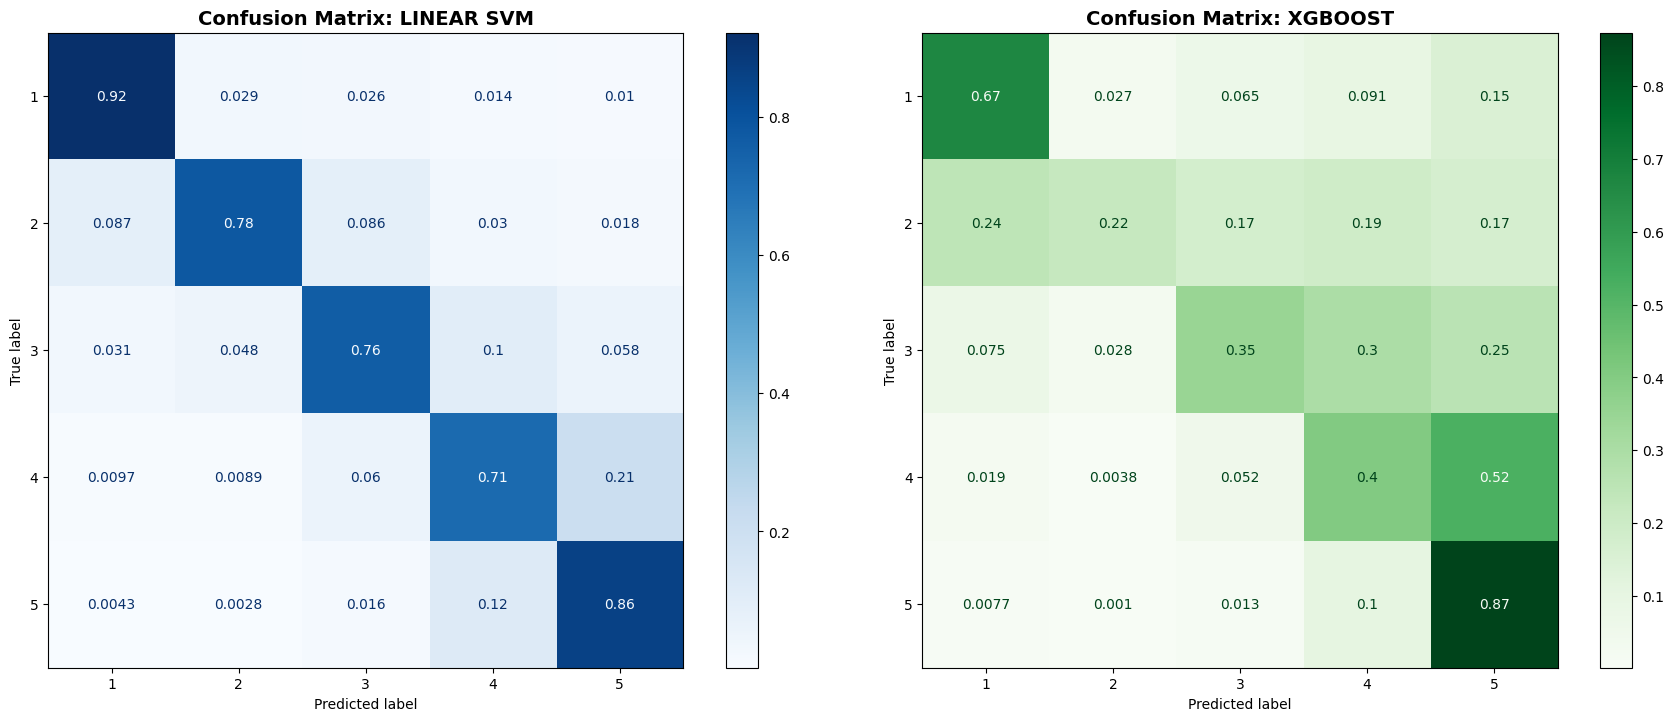

In [23]:
# Predictions
y_pred_svm = svm_pipeline.predict(X_test)

# For XGBoost, we predict (0-4) and add 1 to return to the scale (1-5)
y_pred_xgb = xgb_pipeline.predict(X_test) + 1

# Displaying Classification Reports
models = [("SVM", y_pred_svm), ("XGBoost", y_pred_xgb)]

for name, preds in models:
    print("\n" + "="*60)
    print(f" CLASSIFICATION REPORT: {name}")
    print("="*60)
    print(classification_report(y_test, preds))

# Confusion Matrices Visualization
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# SVM Matrix
cm_svm = confusion_matrix(y_test, y_pred_svm, normalize='true')
disp_svm = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=svm_pipeline.classes_)
disp_svm.plot(ax=axes[0], cmap='Blues')
axes[0].set_title("Confusion Matrix: LINEAR SVM", fontsize=14, fontweight='bold')

# XGBoost Matrix
cm_xgb = confusion_matrix(y_test, y_pred_xgb, normalize='true')
disp_xgb = ConfusionMatrixDisplay(confusion_matrix=cm_xgb, display_labels=svm_pipeline.classes_)
disp_xgb.plot(ax=axes[1], cmap='Greens')
axes[1].set_title("Confusion Matrix: XGBOOST", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

The comparison between **Linear SVM** and **XGBoost** reveals significant differences in how these algorithms handle high-dimensional textual data:

* **Algorithm Suitability:** The **Linear SVM** significantly outperforms XGBoost. This is expected as SVMs are mathematically more robust for high-dimensional, sparse feature spaces (like TF-IDF vectors), whereas XGBoost often struggles with the "curse of dimensionality" in raw text classification.
* **Adjacent Class Confusion:** Both models show a strong diagonal, but with frequent "bleeding" into adjacent classes (e.g., class 4 being predicted as 5). This suggests that the semantic boundary between certain ratings—such as 4 and 5 stars—is highly subjective. A user's decision to give 4 vs. 5 stars often depends more on personal bias than on the specific vocabulary used in the review.
* **Predictive Patterns:** While the models are excellent at identifying "polar" reviews (1 and 5 stars), the middle ground (3 stars) remains the most difficult to classify accurately, often being confused with surrounding ratings.

**Strategic Optimization: Sentiment Grouping**

To improve model reliability and provide a more actionable business tool, we will simplify the target variable. By merging the 5-point scale into **3 distinct sentiment categories**, we reduce "noise" while maintaining the core intent of the feedback:

1.  **Negative (0):** Ratings 1 & 2
2.  **Neutral (1):** Rating 3
3.  **Positive (2):** Ratings 4 & 5

This transition will likely resolve the adjacent class confusion and provide a more robust classifier for final deployment.

##### *3 classes*

In [24]:
# Data Preparation
X = df['lemmatized_review']
y = df['rating'].apply(lambda x: 1 if x <= 2 else (2 if x == 3 else 3))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=24, stratify=y)

# 2. SVM Pipeline
svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1,2))), 
    ('svm', LinearSVC(class_weight='balanced', random_state=24))
])

# XGBoost Pipeline
y_train_xgb = y_train - 1
y_test_xgb = y_test - 1

xgb_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1,2))),
    ('xgb', XGBClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=6,
        objective='multi:softprob',
        random_state=24,
        n_jobs=-1
    ))
])

# Training
print("Training SVM...")
svm_pipeline.fit(X_train, y_train)

print("Training XGBoost...")
xgb_pipeline.fit(X_train, y_train_xgb)

Training SVM...
Training XGBoost...


Pipeline(steps=[('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
                ('xgb',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=False, eval_metric=None,
                               feature_types=None, gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=6, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=200, n_jobs=-1,
                               num_parallel_tree=None,
                               objective='multi:softprob', ...))])


 CLASSIFICATION REPORT: SVM
              precision    recall  f1-score   support

           1       0.89      0.92      0.90      3119
           2       0.79      0.75      0.77      2519
           3       0.95      0.96      0.96     11706

    accuracy                           0.92     17344
   macro avg       0.88      0.88      0.88     17344
weighted avg       0.92      0.92      0.92     17344


 CLASSIFICATION REPORT: XGBoost
              precision    recall  f1-score   support

           1       0.78      0.66      0.72      3119
           2       0.65      0.22      0.33      2519
           3       0.82      0.97      0.89     11706

    accuracy                           0.80     17344
   macro avg       0.75      0.62      0.64     17344
weighted avg       0.79      0.80      0.77     17344



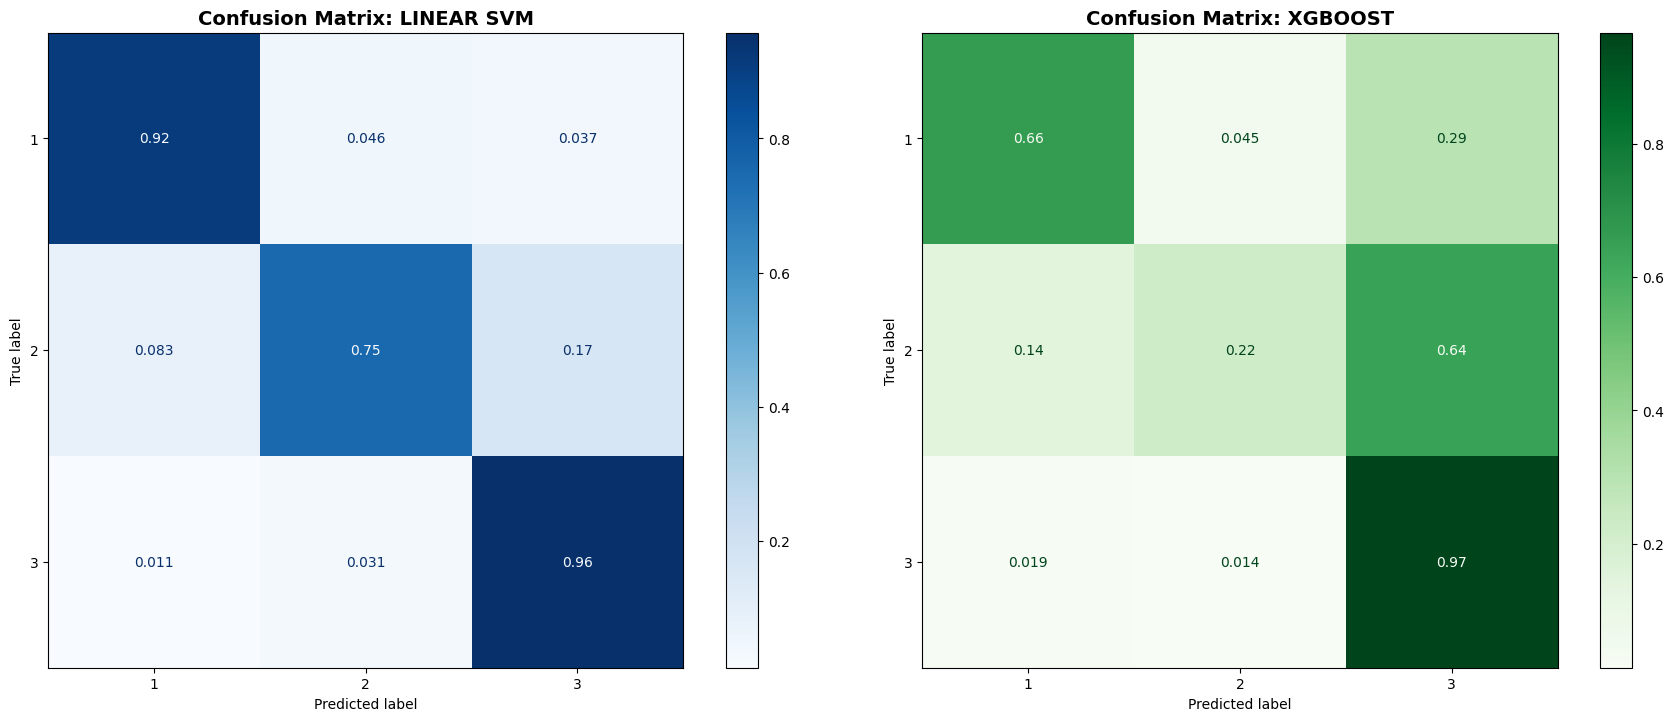

In [25]:
# Predictions
y_pred_svm = svm_pipeline.predict(X_test)

# For XGBoost, we predict (0-4) and add 1 to return to the scale (1-5)
y_pred_xgb = xgb_pipeline.predict(X_test) + 1

# Displaying Classification Reports
models = [("SVM", y_pred_svm), ("XGBoost", y_pred_xgb)]

for name, preds in models:
    print("\n" + "="*60)
    print(f" CLASSIFICATION REPORT: {name}")
    print("="*60)
    print(classification_report(y_test, preds))

# Confusion Matrices Visualization
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# SVM Matrix
cm_svm = confusion_matrix(y_test, y_pred_svm, normalize='true')
disp_svm = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=svm_pipeline.classes_)
disp_svm.plot(ax=axes[0], cmap='Blues')
axes[0].set_title("Confusion Matrix: LINEAR SVM", fontsize=14, fontweight='bold')

# XGBoost Matrix
cm_xgb = confusion_matrix(y_test, y_pred_xgb, normalize='true')
disp_xgb = ConfusionMatrixDisplay(confusion_matrix=cm_xgb, display_labels=svm_pipeline.classes_)
disp_xgb.plot(ax=axes[1], cmap='Greens')
axes[1].set_title("Confusion Matrix: XGBOOST", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

By grouping the ratings into three macro-categories (Negative: 1-2, Neutral: 3, Positive: 4-5), we have significantly reduced the "noise" caused by individual rating subjectivity.

**Performance Highlights:**
* **Overall Accuracy Boost:** As expected, both models show much stronger performance. The **Linear SVM** remains the superior model, achieving near-perfect scores on polar sentiments (0.92 for Negative and 0.96 for Positive).
* **Class 3 (Neutral) Challenge:** Even with grouping, the "Neutral" class remains the most difficult to predict (0.75 for SVM and only 0.22 for XGBoost). 
    * Neutral reviews are often semantically ambiguous, containing both praise and complaints (e.g., "Good sound but the seats were dirty"). This "mixed signal" is harder for the model to distinguish from pure positive or negative reviews.
* **XGBoost Limitation:** XGBoost continues to struggle significantly with the minority/neutral class, showing a high bias toward predicting "Positive" for almost everything (0.64 and 0.97).

**Conclusion:**

The **Linear SVM** on a 3-class distribution is our most reliable production-ready model. It effectively distinguishes between clear dissatisfaction and customer delight, which provides the most actionable insights for business decision-making.

### **BERT**

##### *5 classes*

In [26]:
# Data Preparation
df_llm = df.dropna(subset=['review', 'rating']).copy()
df_llm['label'] = df_llm['rating'].astype(int) - 1

# Dataset creation and split directly via Hugging Face
ds = Dataset.from_pandas(df_llm[['review', 'label']]).train_test_split(test_size=0.2, seed=24)

# Compact Tokenization
checkpoint = "camembert-base"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

def tokenize(batch):
    return tokenizer(batch["review"], truncation=True, padding="max_length", max_length=128)

tokenized_ds = ds.map(tokenize, batched=True)

# Simplified metrics with the 'evaluate' library
accuracy = evaluate.load("accuracy")
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return accuracy.compute(predictions=predictions, references=labels)

# Model and Training
model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=5)

training_args = TrainingArguments(
    output_dir="./results_camembert",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16, 
    num_train_epochs=3,
    fp16=True,                     
    load_best_model_at_end=True,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_ds["train"],
    eval_dataset=tokenized_ds["test"],
    compute_metrics=compute_metrics,
)

trainer.train()

<frozen importlib._bootstrap>:228: DeprecationWarning: builtin type SwigPyPacked has no __module__ attribute
<frozen importlib._bootstrap>:228: DeprecationWarning: builtin type SwigPyObject has no __module__ attribute
Map: 100%|██████████| 17344/17344 [00:02<00:00, 6990.17 examples/s]
Some weights of CamembertForSequenceClassification were not initialized from the model checkpoint at camembert-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy
1,0.859800,0.833703,0.639933
2,0.757700,0.771760,0.673374
3,0.651100,0.760466,0.690325


TrainOutput(global_step=13008, training_loss=0.7867152418157711, metrics={'train_runtime': 2077.1132, 'train_samples_per_second': 100.201, 'train_steps_per_second': 6.263, 'total_flos': 1.3690563188686848e+16, 'train_loss': 0.7867152418157711, 'epoch': 3.0})


 CLASSIFICATION REPORT: CAMEMBERT (Fine-Tuned)
              precision    recall  f1-score   support

           1       0.81      0.79      0.80      1883
           2       0.56      0.53      0.55      1236
           3       0.61      0.59      0.60      2415
           4       0.65      0.51      0.57      5040
           5       0.73      0.86      0.79      6770

    accuracy                           0.69     17344
   macro avg       0.67      0.66      0.66     17344
weighted avg       0.68      0.69      0.68     17344



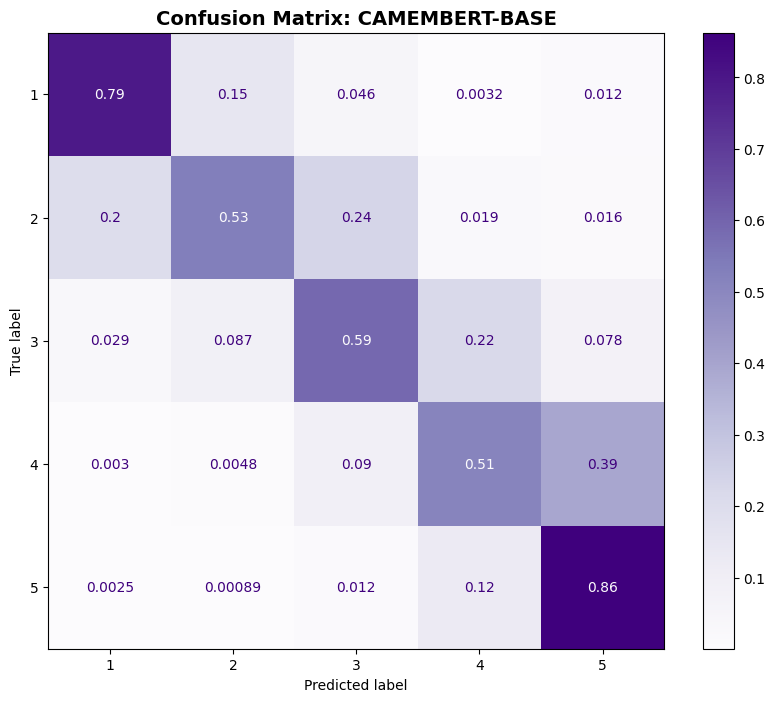

In [27]:
# Predictions on the test set
raw_predictions = trainer.predict(tokenized_ds["test"])
y_pred_cam = np.argmax(raw_predictions.predictions, axis=-1)
y_true_cam = raw_predictions.label_ids

# We scale back from 0-4 to 1-5 for display
y_pred_cam_scaled = y_pred_cam + 1
y_true_cam_scaled = y_true_cam + 1

# Displaying the Classification Report
print("\n" + "="*60)
print(f" CLASSIFICATION REPORT: CAMEMBERT (Fine-Tuned)")
print("="*60)
print(classification_report(y_true_cam_scaled, y_pred_cam_scaled))

# Confusion Matrix Visualization
fig, ax = plt.subplots(figsize=(10, 8))

cm_cam = confusion_matrix(y_true_cam_scaled, y_pred_cam_scaled, normalize='true')
disp_cam = ConfusionMatrixDisplay(
    confusion_matrix=cm_cam, 
    display_labels=[1, 2, 3, 4, 5]
)

disp_cam.plot(ax=ax, cmap='Purples')
ax.set_title("Confusion Matrix: CAMEMBERT-BASE", fontsize=14, fontweight='bold')

plt.show()

##### *3 classes*

In [28]:
# Data Preparation
df_llm = df.dropna(subset=['review', 'rating']).copy()
df_llm['label'] = df_llm['rating'].astype(int) - 1
df_llm['label'] = df_llm['label'].apply(lambda x: 0 if x <= 1 else (1 if x == 2 else 2))

# Dataset creation and split directly via Hugging Face
ds = Dataset.from_pandas(df_llm[['review', 'label']]).train_test_split(test_size=0.2, seed=24)

# Compact Tokenization
checkpoint = "camembert-base"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

def tokenize(batch):
    return tokenizer(batch["review"], truncation=True, padding="max_length", max_length=128)

tokenized_ds = ds.map(tokenize, batched=True)

# Simplified metrics with the 'evaluate' library
accuracy = evaluate.load("accuracy")
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return accuracy.compute(predictions=predictions, references=labels)

# Model and Training
model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=5)

training_args = TrainingArguments(
    output_dir="./results_camembert",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16, 
    num_train_epochs=3,
    fp16=True,                     
    load_best_model_at_end=True,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_ds["train"],
    eval_dataset=tokenized_ds["test"],
    compute_metrics=compute_metrics,
)

trainer.train()

Map: 100%|██████████| 17344/17344 [00:01<00:00, 8958.39 examples/s]
Some weights of CamembertForSequenceClassification were not initialized from the model checkpoint at camembert-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy
1,0.397700,0.371536,0.857703
2,0.318700,0.331672,0.876960
3,0.256500,0.340234,0.886762


TrainOutput(global_step=13008, training_loss=0.35120944928052533, metrics={'train_runtime': 1804.1741, 'train_samples_per_second': 115.359, 'train_steps_per_second': 7.21, 'total_flos': 1.3690563188686848e+16, 'train_loss': 0.35120944928052533, 'epoch': 3.0})


 CLASSIFICATION REPORT: CAMEMBERT (Fine-Tuned)
              precision    recall  f1-score   support

           1       0.88      0.83      0.85      3119
           2       0.60      0.56      0.58      2415
           3       0.93      0.95      0.94     11810

    accuracy                           0.88     17344
   macro avg       0.80      0.78      0.79     17344
weighted avg       0.87      0.88      0.87     17344



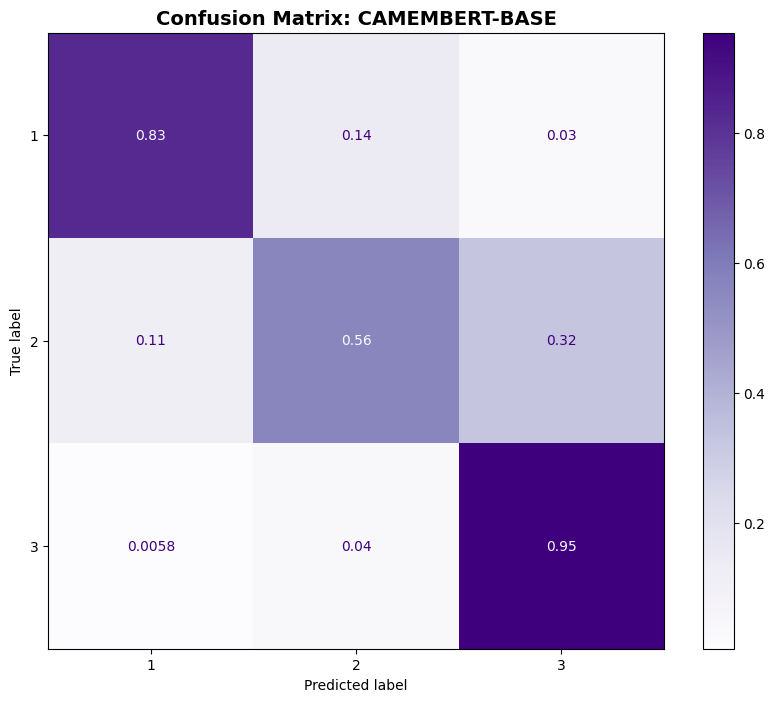

In [30]:
# Predictions on the test set
raw_predictions = trainer.predict(tokenized_ds["test"])
y_pred_cam = np.argmax(raw_predictions.predictions, axis=-1)
y_true_cam = raw_predictions.label_ids

# We scale back from 0-4 to 1-5 for display
y_pred_cam_scaled = y_pred_cam + 1
y_true_cam_scaled = y_true_cam + 1

# Displaying the Classification Report
print("\n" + "="*60)
print(f" CLASSIFICATION REPORT: CAMEMBERT (Fine-Tuned)")
print("="*60)
print(classification_report(y_true_cam_scaled, y_pred_cam_scaled))

# Confusion Matrix Visualization
fig, ax = plt.subplots(figsize=(10, 8))

cm_cam = confusion_matrix(y_true_cam_scaled, y_pred_cam_scaled, normalize='true')
disp_cam = ConfusionMatrixDisplay(
    confusion_matrix=cm_cam, 
    display_labels=[1, 2, 3]
)

disp_cam.plot(ax=ax, cmap='Purples')
ax.set_title("Confusion Matrix: CAMEMBERT-BASE", fontsize=14, fontweight='bold')

plt.show()

The performance is currently lower than the SVM baseline, suggesting the model is still **underfit**. A primary path for improvement would be to **extend the training duration** (increase the number of epochs) to allow the model to fully converge and better capture the semantic nuances of the dataset.